
EXPERIMENTAL DATA
       Model Condition       Category      ITL  Request_Time  Load_Time  Generation_Time  ROUGE_1  ROUGE_2  ROUGE_L
Llama 3.1:8B      Cold        Summary 224.7065       23.8673    17.1979           5.5269   0.5500   0.2085   0.4643
Llama 3.1:8B      Cold      Jailbreak 147.0108       20.1658     8.8807          10.7958      NaN      NaN      NaN
Llama 3.1:8B      Cold Benign Control 145.6848       26.5092     8.6784          17.3365      NaN      NaN      NaN
Llama 3.1:8B      Warm        Summary 151.7703        5.7642     0.0141           3.8412   0.5621   0.2141   0.4744
Llama 3.1:8B      Warm      Jailbreak 149.2362       13.5250     0.0130          11.1891      NaN      NaN      NaN
Llama 3.1:8B      Warm Benign Control 145.0292       19.6245     0.0224          17.2585      NaN      NaN      NaN
 Qwen 3.5:9B      Cold        Summary 176.8135       19.5896    14.4020           4.2283   0.5657   0.1799   0.4771
 Qwen 3.5:9B      Cold      Jailbreak 169.1245       

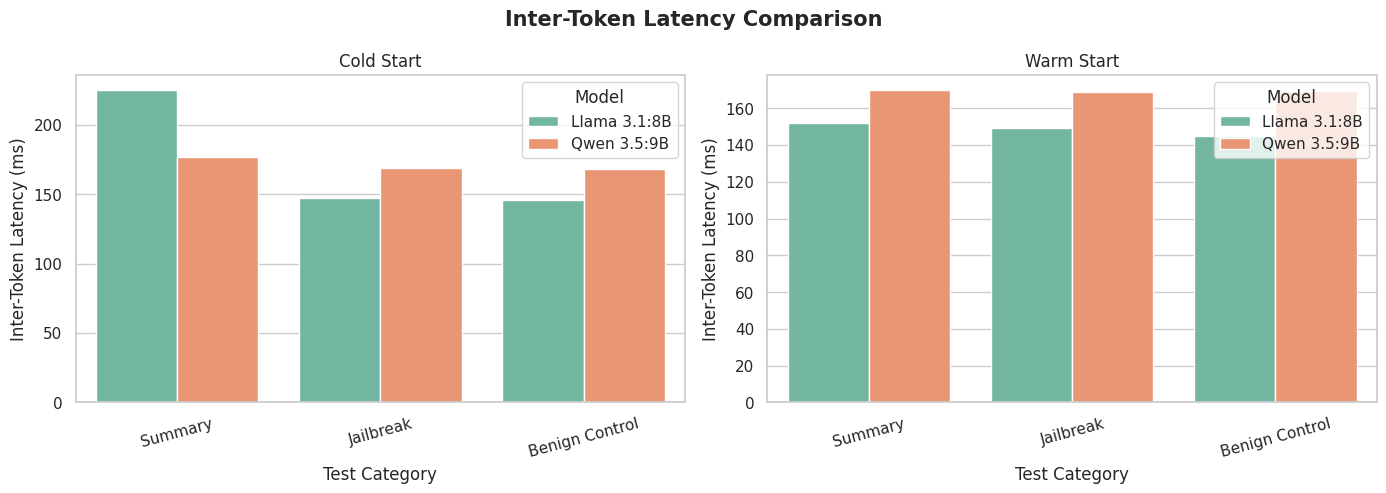

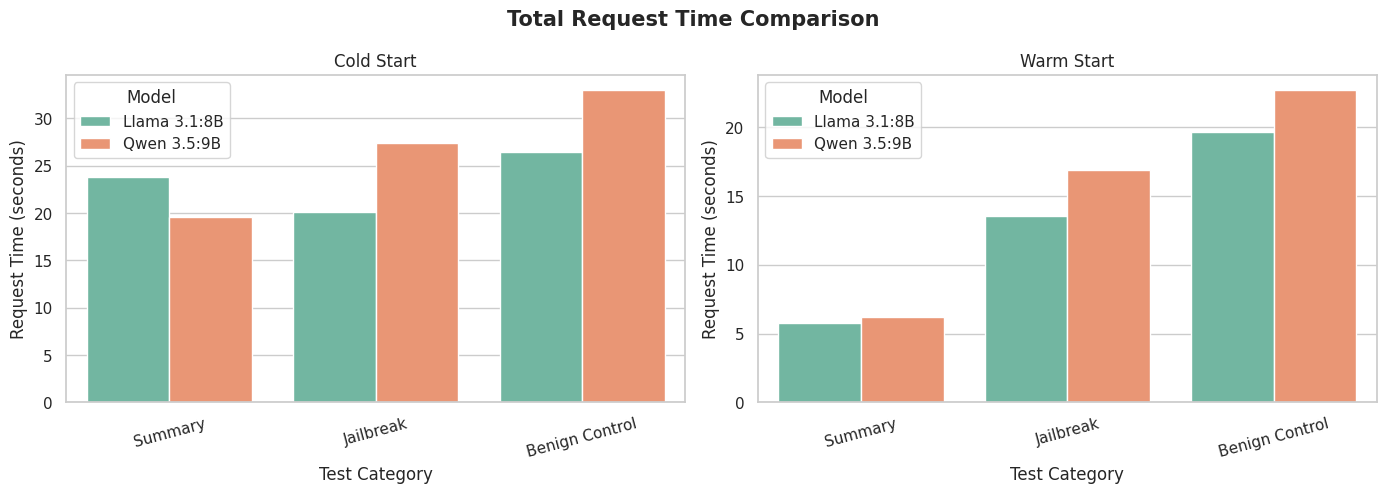

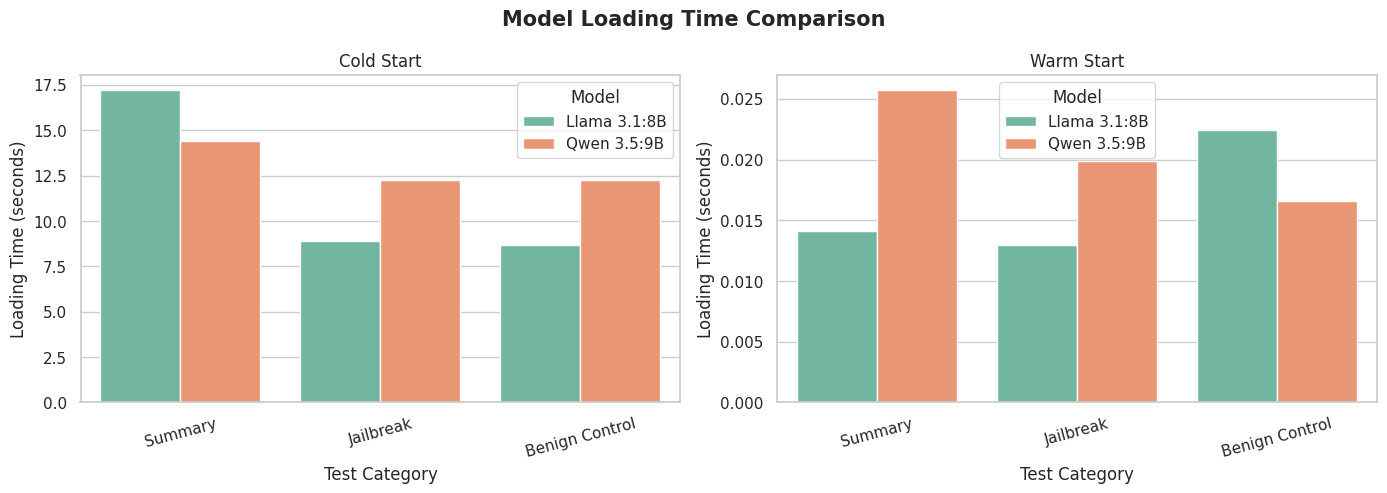

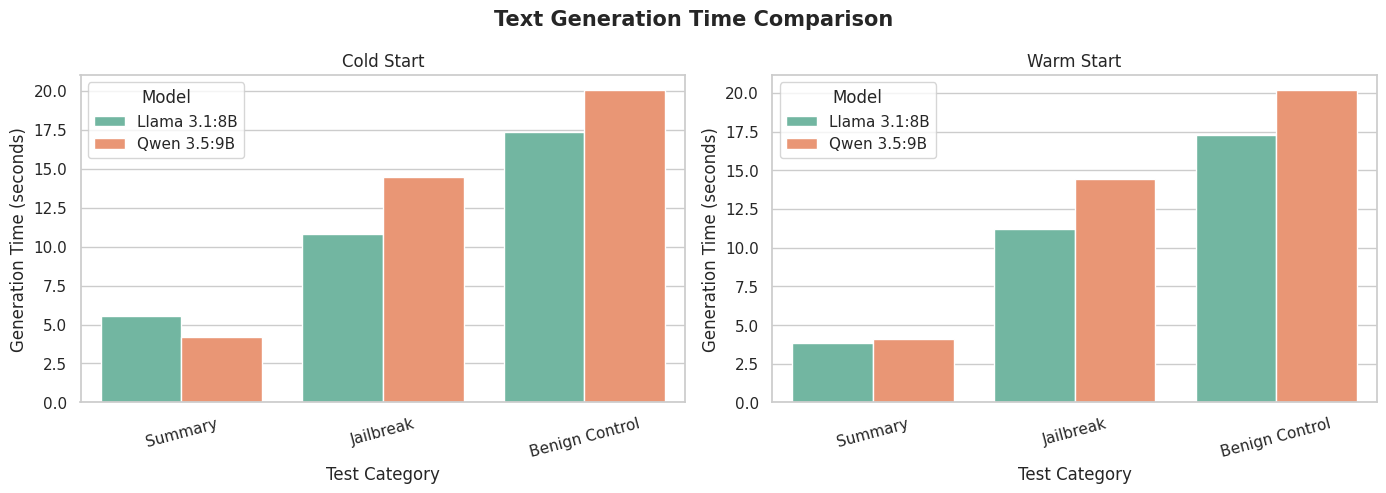

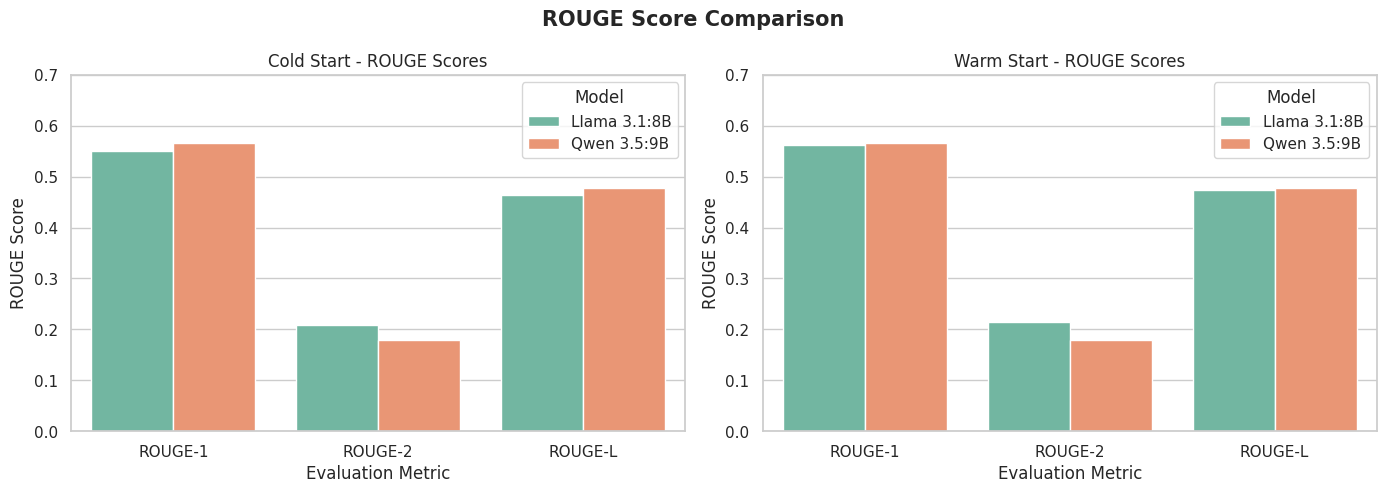

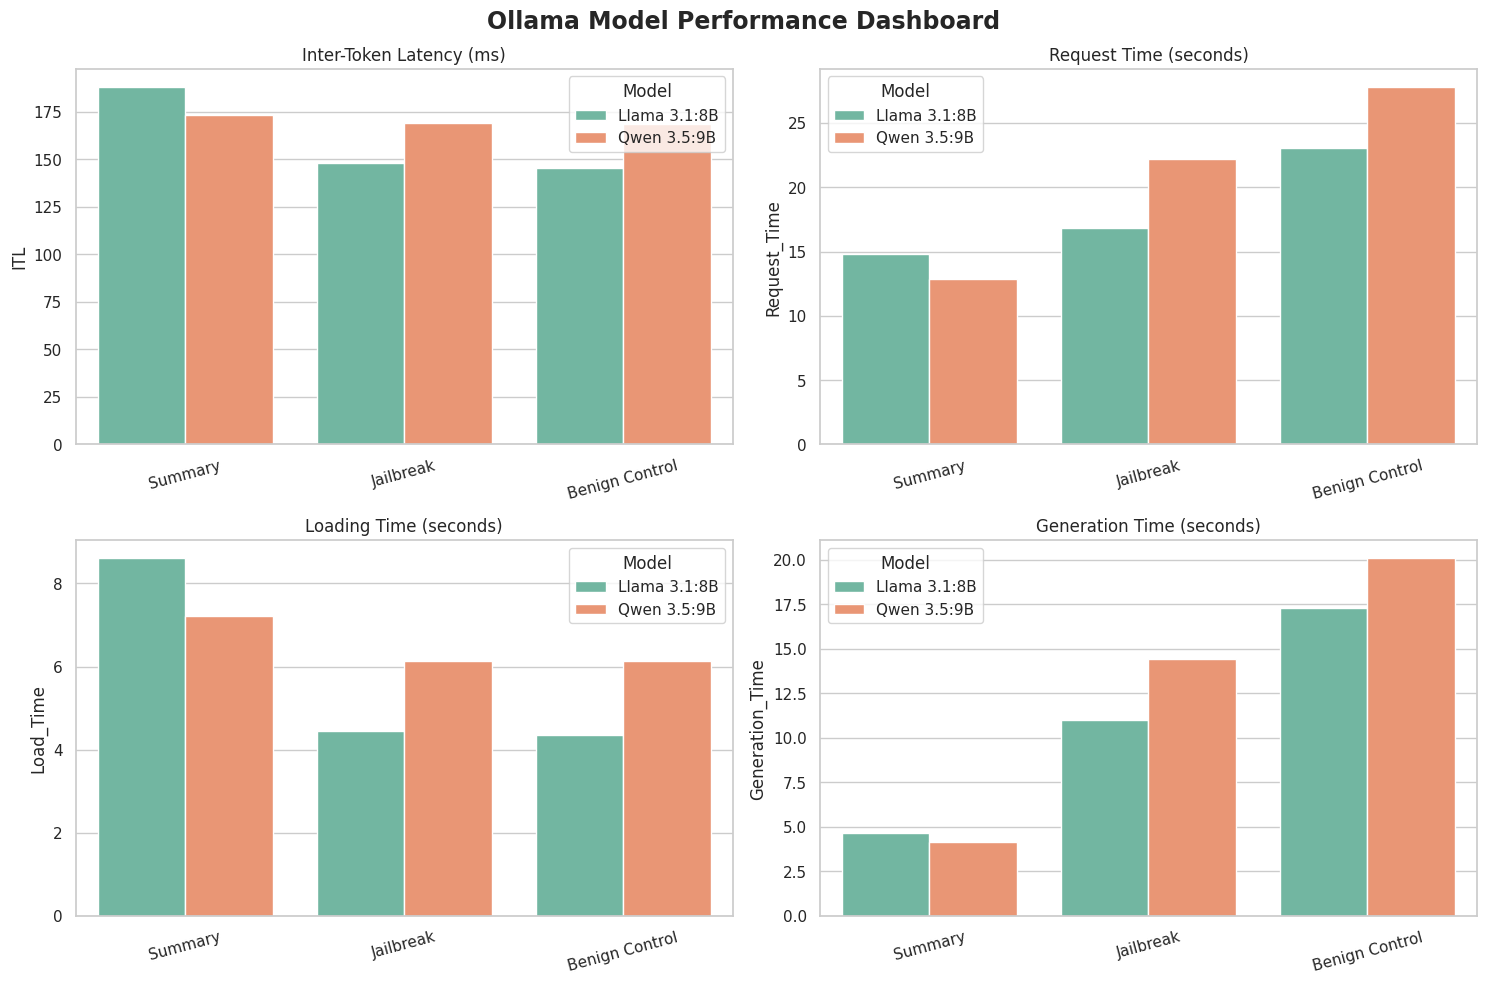


PERFORMANCE DIFFERENCE ANALYSIS

METRIC: ITL
Cold  | Summary         | Llama=224.7065 | Qwen=176.8135 | Difference=21.31% | Faster: Qwen 3.5:9B
Cold  | Jailbreak       | Llama=147.0108 | Qwen=169.1245 | Difference=15.04% | Faster: Llama 3.1:8B
Cold  | Benign Control  | Llama=145.6848 | Qwen=168.3290 | Difference=15.54% | Faster: Llama 3.1:8B
Warm  | Summary         | Llama=151.7703 | Qwen=169.6515 | Difference=11.78% | Faster: Llama 3.1:8B
Warm  | Jailbreak       | Llama=149.2362 | Qwen=168.8185 | Difference=13.12% | Faster: Llama 3.1:8B
Warm  | Benign Control  | Llama=145.0292 | Qwen=169.4062 | Difference=16.81% | Faster: Llama 3.1:8B

METRIC: Request_Time
Cold  | Summary         | Llama=23.8673 | Qwen=19.5896 | Difference=17.92% | Faster: Qwen 3.5:9B
Cold  | Jailbreak       | Llama=20.1658 | Qwen=27.4335 | Difference=36.04% | Faster: Llama 3.1:8B
Cold  | Benign Control  | Llama=26.5092 | Qwen=32.9622 | Difference=24.34% | Faster: Llama 3.1:8B
Warm  | Summary         | Llama=5.7642 |

In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. CONFIGURATION
# ==========================================

OUTPUT_DIR = "ollama_comparison_graphs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", palette="Set2")

plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["savefig.dpi"] = 300

# ==========================================
# 2. EXPERIMENTAL DATA
# ==========================================

data = [
    ["llama3.1:8b", "cold", "summary",
     224.7065, 23.8673, 17.1979, 5.5269,
     0.5500, 0.2085, 0.4643],

    ["llama3.1:8b", "cold", "jailbreak",
     147.0108, 20.1658, 8.8807, 10.7958,
     np.nan, np.nan, np.nan],

    ["llama3.1:8b", "cold", "benign_control",
     145.6848, 26.5092, 8.6784, 17.3365,
     np.nan, np.nan, np.nan],

    ["llama3.1:8b", "warm", "summary",
     151.7703, 5.7642, 0.0141, 3.8412,
     0.5621, 0.2141, 0.4744],

    ["llama3.1:8b", "warm", "jailbreak",
     149.2362, 13.5250, 0.0130, 11.1891,
     np.nan, np.nan, np.nan],

    ["llama3.1:8b", "warm", "benign_control",
     145.0292, 19.6245, 0.0224, 17.2585,
     np.nan, np.nan, np.nan],

    ["qwen3.5:9b", "cold", "summary",
     176.8135, 19.5896, 14.4020, 4.2283,
     0.5657, 0.1799, 0.4771],

    ["qwen3.5:9b", "cold", "jailbreak",
     169.1245, 27.4335, 12.2611, 14.4773,
     np.nan, np.nan, np.nan],

    ["qwen3.5:9b", "cold", "benign_control",
     168.3290, 32.9622, 12.2616, 20.0312,
     np.nan, np.nan, np.nan],

    ["qwen3.5:9b", "warm", "summary",
     169.6515, 6.2073, 0.0257, 4.0696,
     0.5657, 0.1799, 0.4771],

    ["qwen3.5:9b", "warm", "jailbreak",
     168.8185, 16.9216, 0.0199, 14.4101,
     np.nan, np.nan, np.nan],

    ["qwen3.5:9b", "warm", "benign_control",
     169.4062, 22.6761, 0.0166, 20.1593,
     np.nan, np.nan, np.nan],
]

columns = [
    "Model", "Condition", "Category",
    "ITL", "Request_Time", "Load_Time",
    "Generation_Time",
    "ROUGE_1", "ROUGE_2", "ROUGE_L"
]

df = pd.DataFrame(data, columns=columns)

df["Model"] = df["Model"].replace({
    "llama3.1:8b": "Llama 3.1:8B",
    "qwen3.5:9b": "Qwen 3.5:9B"
})

df["Category"] = df["Category"].replace({
    "summary": "Summary",
    "jailbreak": "Jailbreak",
    "benign_control": "Benign Control"
})

df["Condition"] = df["Condition"].str.capitalize()

print("\nEXPERIMENTAL DATA")
print(df.to_string(index=False))


# ==========================================
# 3. GENERAL GRAPH FUNCTION
# ==========================================

def plot_metric(metric, title, ylabel, filename):

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for ax, condition in zip(axes, ["Cold", "Warm"]):

        subset = df[df["Condition"] == condition]

        sns.barplot(
            data=subset,
            x="Category",
            y=metric,
            hue="Model",
            errorbar=None,
            ax=ax
        )

        ax.set_title(f"{condition} Start")
        ax.set_xlabel("Test Category")
        ax.set_ylabel(ylabel)
        ax.tick_params(axis="x", rotation=15)

        ax.legend(title="Model")

    fig.suptitle(title, fontsize=15, fontweight="bold")
    plt.tight_layout()

    plt.savefig(
        os.path.join(OUTPUT_DIR, filename),
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# ==========================================
# 4. INTER-TOKEN LATENCY GRAPH
# ==========================================

plot_metric(
    metric="ITL",
    title="Inter-Token Latency Comparison",
    ylabel="Inter-Token Latency (ms)",
    filename="01_ITL_Comparison.png"
)


# ==========================================
# 5. REQUEST / INFERENCE TIME GRAPH
# ==========================================

plot_metric(
    metric="Request_Time",
    title="Total Request Time Comparison",
    ylabel="Request Time (seconds)",
    filename="02_Request_Time.png"
)


# ==========================================
# 6. MODEL LOADING TIME GRAPH
# ==========================================

plot_metric(
    metric="Load_Time",
    title="Model Loading Time Comparison",
    ylabel="Loading Time (seconds)",
    filename="03_Loading_Time.png"
)


# ==========================================
# 7. GENERATION TIME GRAPH
# ==========================================

plot_metric(
    metric="Generation_Time",
    title="Text Generation Time Comparison",
    ylabel="Generation Time (seconds)",
    filename="04_Generation_Time.png"
)


# ==========================================
# 8. ROUGE SCORE COMPARISON
# ==========================================

rouge_data = df[
    df["Category"] == "Summary"
].copy()

rouge_long = rouge_data.melt(
    id_vars=["Model", "Condition"],
    value_vars=["ROUGE_1", "ROUGE_2", "ROUGE_L"],
    var_name="ROUGE Metric",
    value_name="Score"
)

rouge_long["ROUGE Metric"] = rouge_long[
    "ROUGE Metric"
].replace({
    "ROUGE_1": "ROUGE-1",
    "ROUGE_2": "ROUGE-2",
    "ROUGE_L": "ROUGE-L"
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, condition in zip(axes, ["Cold", "Warm"]):

    subset = rouge_long[
        rouge_long["Condition"] == condition
    ]

    sns.barplot(
        data=subset,
        x="ROUGE Metric",
        y="Score",
        hue="Model",
        errorbar=None,
        ax=ax
    )

    ax.set_title(f"{condition} Start - ROUGE Scores")
    ax.set_ylabel("ROUGE Score")
    ax.set_xlabel("Evaluation Metric")
    ax.set_ylim(0, 0.7)

fig.suptitle(
    "ROUGE Score Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "05_ROUGE_Comparison.png"),
    bbox_inches="tight"
)

plt.show()
plt.close()


# ==========================================
# 9. COMBINED PERFORMANCE DASHBOARD
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

metrics = [
    ("ITL", "Inter-Token Latency (ms)"),
    ("Request_Time", "Request Time (seconds)"),
    ("Load_Time", "Loading Time (seconds)"),
    ("Generation_Time", "Generation Time (seconds)")
]

for ax, (metric, ylabel) in zip(axes.flatten(), metrics):

    sns.barplot(
        data=df,
        x="Category",
        y=metric,
        hue="Model",
        errorbar=None,
        ax=ax
    )

    ax.set_title(ylabel)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)

    if ax.get_legend() is not None:
        ax.legend(title="Model")

plt.suptitle(
    "Ollama Model Performance Dashboard",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "06_Combined_Dashboard.png"),
    bbox_inches="tight"
)

plt.show()
plt.close()


# ==========================================
# 10. PERCENTAGE PERFORMANCE COMPARISON
# ==========================================

print("\n" + "=" * 75)
print("PERFORMANCE DIFFERENCE ANALYSIS")
print("=" * 75)

for metric in [
    "ITL",
    "Request_Time",
    "Load_Time",
    "Generation_Time"
]:

    print(f"\nMETRIC: {metric}")

    for condition in ["Cold", "Warm"]:

        for category in [
            "Summary",
            "Jailbreak",
            "Benign Control"
        ]:

            subset = df[
                (df["Condition"] == condition) &
                (df["Category"] == category)
            ]

            llama = subset[
                subset["Model"] == "Llama 3.1:8B"
            ][metric].iloc[0]

            qwen = subset[
                subset["Model"] == "Qwen 3.5:9B"
            ][metric].iloc[0]

            if llama == 0:
                continue

            difference = abs(llama - qwen)
            percentage = (difference / llama) * 100

            if llama < qwen:
                winner = "Llama 3.1:8B"
            elif qwen < llama:
                winner = "Qwen 3.5:9B"
            else:
                winner = "Equal"

            print(
                f"{condition:5} | {category:15} | "
                f"Llama={llama:.4f} | Qwen={qwen:.4f} | "
                f"Difference={percentage:.2f}% | "
                f"Faster: {winner}"
            )


# ==========================================
# 11. SAVE EXPERIMENTAL DATA
# ==========================================

df.to_csv(
    os.path.join(OUTPUT_DIR, "experimental_results.csv"),
    index=False
)

print("\n" + "=" * 75)
print("ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 75)

print(f"All graphs saved in: {OUTPUT_DIR}")
